# RAG – Sumários Executivos dos Planos de Desenvolvimento (ANP)

Pipeline RAG completo sobre os PDFs publicados em
<https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/planos-de-desenvolvimento>

| Etapa | O que faz |
|---|---|
| 0 | Configuração e dependências |
| 1 | **Aquisição**: descobre e baixa os PDFs de todos os campos |
| 2 | **Carga (loading)**: extrai texto por página |
| 3 | **Limpeza** do texto |
| 4 | **Chunking** com metadados (campo, arquivo, página) |
| 5 | **Embeddings** (modelo multilíngue local) |
| 6 | **Vector store** (FAISS, persistido em disco) |
| 7 | **Retrieval** denso + BM25 (híbrido, RRF) com filtro por campo |
| 8 | **Augmentation**: montagem do prompt com contexto e citações |
| 9 | **Generation**: LLM (Claude) ou fallback extrativo |
| 10 | Pipeline `perguntar()` ponta a ponta |
| 11 | **Avaliação** de retrieval (hit rate / MRR) |

## Etapa 0 – Dependências e configuração

Requer **Python 3.9–3.12**. Recomendado criar um ambiente virtual e instalar as dependências com versões fixadas (`requirements.txt`, na mesma pasta do notebook):

```
python -m venv .venv && .venv\Scriptsctivate      # Linux/macOS: source .venv/bin/activate
pip install -r requirements.txt
```

A célula abaixo faz o mesmo `pip install` no kernel atual, caso prefira rodar daqui. Se `torch` já estiver instalado e funcionando, ela não o altera. Para GPU NVIDIA, instale antes o torch com CUDA (https://pytorch.org/get-started/locally/).

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, html, time, unicodedata, pickle
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import requests
from tqdm.auto import tqdm

BASE_DIR   = Path.cwd()   # pasta do notebook: PDFs em ./planos, indice em ./index
PDF_DIR    = BASE_DIR / "planos"
INDEX_DIR  = BASE_DIR / "index"
PDF_DIR.mkdir(parents=True, exist_ok=True)
INDEX_DIR.mkdir(parents=True, exist_ok=True)

PAGE_URL = ("https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/"
            "desenvolvimento-e-producao/planos-de-desenvolvimento")
HEADERS = {"User-Agent": "Mozilla/5.0"}

EMBED_MODEL   = "intfloat/multilingual-e5-small"   # troque por -base/-large p/ mais qualidade
CHUNK_SIZE    = 1000      # caracteres
CHUNK_OVERLAP = 150
TOP_K         = 6
LLM_MODEL     = "claude-sonnet-5-5"   # usa ANTHROPIC_API_KEY; sem chave, cai no modo extrativo

D:\rag_anp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Etapa 1 – Aquisição dos documentos
Lê a página da ANP, coleta todos os links de PDF dos sumários executivos (o nome do campo vem do texto do link) e baixa para `./planos` (ao lado do notebook). Arquivos já baixados são pulados.

In [3]:
def descobrir_pdfs():
    page = requests.get(PAGE_URL, headers=HEADERS, timeout=60).text
    itens = {}
    for m in re.finditer(r'<a[^>]*href="([^"]+\.pdf)"[^>]*>(.*?)</a>', page, re.S):
        url = m.group(1)
        nome = html.unescape(re.sub(r"<[^>]+>", "", m.group(2))).strip()
        if "/desenvolvimento-e-producao/" in url and nome:   # ignora PDFs de rodapé/LGPD
            itens.setdefault(url, nome)
    return itens

def baixar(item):
    url, campo = item
    destino = PDF_DIR / url.rsplit("/", 1)[-1]
    if destino.exists() and destino.stat().st_size > 1000:
        return dict(url=url, campo=campo, arquivo=destino.name, status="ok")
    erro = None
    for _ in range(3):
        try:
            r = requests.get(url, headers=HEADERS, timeout=120)
            if r.status_code == 200 and r.content[:4] == b"%PDF":
                destino.write_bytes(r.content)
                return dict(url=url, campo=campo, arquivo=destino.name, status="ok")
            erro = r.status_code
        except Exception as e:
            erro = str(e)
        time.sleep(2)
    return dict(url=url, campo=campo, arquivo=destino.name, status=f"erro {erro}")

itens = descobrir_pdfs()
with ThreadPoolExecutor(6) as ex:
    manifesto = list(tqdm(ex.map(baixar, itens.items()), total=len(itens)))
(BASE_DIR / "manifesto_planos.json").write_text(json.dumps(manifesto, ensure_ascii=False, indent=1), encoding="utf-8")
print(len(manifesto), "PDFs;", sum(m["status"] == "ok" for m in manifesto), "ok")
print([m for m in manifesto if m["status"] != "ok"])

  0%|          | 0/428 [00:00<?, ?it/s]

100%|██████████| 428/428 [00:00<00:00, 32915.80it/s]

428 PDFs; 428 ok
[]


## Etapa 2 – Carga (loading)
Extrai o texto página a página com `pypdf`. PDFs sem camada de texto (escaneados) são listados — precisariam de OCR.

In [4]:
from pypdf import PdfReader
import logging; logging.getLogger("pypdf").setLevel(logging.ERROR)

def carregar_pdf(m):
    try:
        r = PdfReader(PDF_DIR / m["arquivo"])
        return [dict(campo=m["campo"], arquivo=m["arquivo"], url=m["url"], pagina=i + 1,
                     texto=p.extract_text() or "") for i, p in enumerate(r.pages)]
    except Exception as e:
        print("falha:", m["arquivo"], e); return []

paginas = []
for m in tqdm([m for m in manifesto if m["status"] == "ok"]):
    paginas += carregar_pdf(m)

sem_texto = {}
for p in paginas:
    sem_texto.setdefault(p["arquivo"], [0, 0])
    sem_texto[p["arquivo"]][1] += 1
    if len(p["texto"].strip()) < 30: sem_texto[p["arquivo"]][0] += 1
escaneados = [a for a, (v, t) in sem_texto.items() if v == t]
print(f"{len(paginas)} páginas de {len(sem_texto)} PDFs; sem texto (precisam OCR): {len(escaneados)}")
escaneados[:20]

  0%|          | 0/428 [00:00<?, ?it/s]

  1%|          | 4/428 [00:00<00:14, 28.94it/s]

  2%|▏         | 7/428 [00:00<00:14, 29.34it/s]

  3%|▎         | 11/428 [00:00<00:14, 29.45it/s]

  3%|▎         | 14/428 [00:00<00:15, 26.49it/s]

  4%|▍         | 17/428 [00:00<00:15, 26.48it/s]

... (127 outputs left out)

100%|█████████▉| 427/428 [00:16<00:00, 24.25it/s]

100%|██████████| 428/428 [00:16<00:00, 25.64it/s]

1123 páginas de 428 PDFs; sem texto (precisam OCR): 0


[]

## Etapa 3 – Limpeza
Normaliza unicode, remove hifenização de quebra de linha, espaços e linhas repetidas (cabeçalhos/rodapés que aparecem em muitas páginas do mesmo documento).

In [5]:
from collections import Counter

def limpar_texto(t):
    t = unicodedata.normalize("NFC", t)
    t = t.replace("\x00", " ").replace("\u00a0", " ")
    t = re.sub(r"(\w)-\n(\w)", r"\1\2", t)          # palavra hifenizada na quebra de linha
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\n\s*\n+", "\n\n", t)
    return t.strip()

def remover_repetidas(paginas):
    """Remove linhas que se repetem em >=40% das páginas de um documento (cabeçalho/rodapé)."""
    por_doc = {}
    for p in paginas: por_doc.setdefault(p["arquivo"], []).append(p)
    for pgs in por_doc.values():
        if len(pgs) < 5: continue
        c = Counter(l.strip() for p in pgs for l in set(p["texto"].split("\n")) if 3 < len(l.strip()) < 120)
        ruido = {l for l, n in c.items() if n >= 0.4 * len(pgs)}
        for p in pgs:
            p["texto"] = "\n".join(l for l in p["texto"].split("\n") if l.strip() not in ruido)
    return paginas

for p in paginas: p["texto"] = limpar_texto(p["texto"])
paginas = remover_repetidas(paginas)
paginas = [p for p in paginas if len(p["texto"]) >= 30]
print(len(paginas), "páginas úteis")
print(paginas[0]["texto"][:600])

907 páginas úteis
ABALONE 2016 

Plano de Desenvolvimento Aprovado 
Reunião de Diretoria nº 827 de 24/11/2015 
Resolução nº 964/2015 

Localização: O campo de Abalone, com área de desenvolvimento de 21,106km², está localizado ao 
norte da Bacia de Campos, a 120km a sudeste da cidade de Vitória, capital do Estado de Espírito 
Santo, na costa do Brasil, em lâmina d'água que varia em torno de 1890 a 1940m. 

Figura 1- Mapa de localização do Campo de ABALONE. 
Sistema de Produção e Escoame nto: A unidade de Produção do Campo de Abalone é o FPSO 
(Floating Production Storage and Offloading) Espírito Santo. Os fluido


## Etapa 4 – Chunking
Divisão recursiva (parágrafo → linha → frase → palavra) com sobreposição. Cada chunk guarda `campo`, `arquivo` e `pagina`, e o texto indexado é prefixado com o nome do campo — assim perguntas como *"qual a produção de Búzios?"* casam mesmo quando a página não repete o nome.

In [6]:
SEPARADORES = ["\n\n", "\n", ". ", " "]

def cauda(texto, ov):
    """Últimos ~ov caracteres, começando em limite de palavra (não corta no meio)."""
    t = texto[-ov:]
    m = re.search(r"\s", t)
    return t[m.end():] if m and len(texto) > ov else t

def dividir(texto, tam=CHUNK_SIZE, ov=CHUNK_OVERLAP, seps=SEPARADORES):
    if len(texto) <= tam: return [texto]
    sep = next((s for s in seps if s in texto), None)
    if sep is None:
        return [texto[i:i + tam] for i in range(0, len(texto), tam - ov)]
    resto = seps[seps.index(sep) + 1:] or [" "]
    atual, saida = "", []
    for parte in texto.split(sep):
        cand = (atual + sep + parte) if atual else parte
        if len(cand) <= tam:
            atual = cand; continue
        if atual: saida.append(atual)
        if len(parte) > tam:
            saida += dividir(parte, tam, ov, resto); atual = ""
        else:
            atual = (cauda(atual, ov) + sep + parte) if atual and ov else parte
    if atual: saida.append(atual)
    return saida

chunks = []
for p in tqdm(paginas):
    for c in dividir(p["texto"]):
        if len(c.strip()) < 60: continue
        chunks.append(dict(id=len(chunks), campo=p["campo"], arquivo=p["arquivo"], url=p["url"],
                           pagina=p["pagina"], texto=c.strip()))
print(len(chunks), "chunks; tamanho médio:", int(np.mean([len(c["texto"]) for c in chunks])))
chunks[100]

  0%|          | 0/907 [00:00<?, ?it/s]

100%|██████████| 907/907 [00:00<00:00, 239244.94it/s]

1693 chunks; tamanho médio: 733


{'id': 100,
 'campo': 'Aratum',
 'arquivo': 'aratum.pdf',
 'url': 'https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/aratum.pdf',
 'pagina': 1,
 'texto': 'ARATUM 2016 \n\nConcessionário: Participação (%): \nPetróleo Brasileiro S.A. 100 \n\nLocalização: O Campo de Aratum, com área de desenvolvimento de 19,959 km², localiza -se na \nplataforma continental da Bacia Potiguar, em lâmina d’água rasa (6 m). O campo é desenvolvi do com a \nutilização de jaquetas de produção (PART I - área do 1-RNS-43 e PART II - área do 1-RNS-48), por se \ntratar de campo marítimo e afastado da linha de costa. \n\nARATUM \nNº do Contrato: 48000.003780/97-45 \nOperador do Contrato: Petróleo Brasileiro S.A. \nEstado: Rio Grande do Norte \nBacia: Potiguar \nLocalização: MAR \nLâmina d´água: 6 m \nFluido Principal: ÓLEO \nÁrea: 19,959 km² \nSituação: Produção \nDescoberta: 09/12/1982 \nDeclaração de Comercialidade: \nInício de Produção: 31/03/1987 \nPrevisão de

## Etapa 5 – Embeddings
Modelo multilíngue local (`multilingual-e5`, bom para português). O E5 exige prefixos `passage:` / `query:`. Vetores normalizados → produto interno = similaridade de cosseno.

In [7]:
from sentence_transformers import SentenceTransformer
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBED_MODEL, device=device)

def texto_indexado(c): return f"passage: Campo {c['campo']}. {c['texto']}"

import hashlib
emb_path, hash_path = INDEX_DIR / "embeddings.npy", INDEX_DIR / "embeddings.sha256"
# o cache só vale se modelo e conteúdo dos chunks forem idênticos
assinatura = hashlib.sha256((EMBED_MODEL + chr(10).join(texto_indexado(c) for c in chunks)).encode("utf-8")).hexdigest()
if emb_path.exists() and hash_path.exists() and hash_path.read_text() == assinatura:
    embeddings = np.load(emb_path)
else:
    embeddings = embedder.encode([texto_indexado(c) for c in chunks], batch_size=64,
                                 normalize_embeddings=True, show_progress_bar=True).astype("float32")
    np.save(emb_path, embeddings); hash_path.write_text(assinatura)
print(embeddings.shape, device)

Batches:   0%|          | 0/27 [00:00<?, ?it/s]

D:\rag_anp\.venv\Lib\site-packages\transformers\models\bert\modeling_bert.py:440: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:555.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


Batches:   4%|▎         | 1/27 [00:00<00:06,  4.08it/s]

Batches:   7%|▋         | 2/27 [00:00<00:04,  5.80it/s]

Batches:  11%|█         | 3/27 [00:00<00:03,  7.08it/s]

Batches:  15%|█▍        | 4/27 [00:00<00:02,  7.91it/s]

... (9 outputs left out)

Batches:  81%|████████▏ | 22/27 [00:02<00:00, 13.31it/s]

Batches:  93%|█████████▎| 25/27 [00:02<00:00, 15.65it/s]

Batches: 100%|██████████| 27/27 [00:02<00:00, 11.85it/s]

(1693, 384) cuda


## Etapa 6 – Vector store
Índice FAISS (`IndexFlatIP`, busca exata) persistido em `./index`, junto com os chunks.

In [8]:
import faiss

index = faiss.IndexFlatIP(embeddings.shape[1])
index.add(embeddings)
faiss.write_index(index, str(INDEX_DIR / "faiss.index"))
(INDEX_DIR / "chunks.pkl").write_bytes(pickle.dumps(chunks))
print("vetores no índice:", index.ntotal)

# Para recarregar em outra sessão (pulando etapas 1–6):
# index = faiss.read_index(str(INDEX_DIR/"faiss.index")); chunks = pickle.loads((INDEX_DIR/"chunks.pkl").read_bytes())

vetores no índice: 1693


## Etapa 7 – Retrieval
Busca **híbrida**: densa (embeddings) + lexical (BM25), combinadas por *Reciprocal Rank Fusion*. Se a pergunta citar um campo pelo nome, o resultado é filtrado para aquele campo.

In [9]:
from rank_bm25 import BM25Okapi

def sem_acento(s): return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn").lower()
def tokenizar(s): return re.findall(r"\w+", sem_acento(s))

bm25 = BM25Okapi([tokenizar(f"{c['campo']} {c['texto']}") for c in chunks])

# nomes de campos, do mais longo ao mais curto (evita "Albacora" casar antes de "Albacora Leste")
campos = sorted({c["campo"] for c in chunks}, key=len, reverse=True)

def detectar_campo(pergunta):
    q = " " + " ".join(tokenizar(pergunta)) + " "
    for c in campos:
        if f" {' '.join(tokenizar(c))} " in q: return c
    return None

_QCACHE = {}
def _qvec(pergunta):
    if pergunta not in _QCACHE:
        _QCACHE[pergunta] = embedder.encode(["query: " + pergunta], normalize_embeddings=True)[0].astype("float32")
    return _QCACHE[pergunta]

def recuperar(pergunta, k=TOP_K, campo=None, rrf_k=60, candidatos=50, modo="hibrido", filtrar=True):
    """modo: 'hibrido' (denso + BM25 via RRF), 'denso' ou 'bm25'.
    filtrar=False ignora o nome de campo citado na pergunta (usado na avaliação)."""
    campo = (campo or detectar_campo(pergunta)) if filtrar else None
    permitido = None if campo is None else np.array([c["campo"] == campo for c in chunks])

    sims = embeddings @ _qvec(pergunta)
    if permitido is not None: sims = np.where(permitido, sims, -1)
    listas = []
    if modo in ("hibrido", "denso"):
        listas.append(np.argsort(-sims)[:candidatos])
    if modo in ("hibrido", "bm25"):
        bs = bm25.get_scores(tokenizar(pergunta))
        if permitido is not None: bs = np.where(permitido, bs, -1)
        listas.append(np.argsort(-bs)[:candidatos])

    score = {}
    for r in listas:
        for pos, i in enumerate(r): score[int(i)] = score.get(int(i), 0) + 1 / (rrf_k + pos + 1)
    top = sorted(score, key=score.get, reverse=True)[:k]
    return [dict(chunks[i], score=score[i], sim=float(sims[i])) for i in top], campo

res, campo = recuperar("Qual a produção prevista do campo de Búzios?")
print("campo detectado:", campo)
for r in res[:3]: print(f"[{r['campo']} p.{r['pagina']}] {r['texto'][:200]!r}\n")

campo detectado:

 Búzios
[Búzios p.1] 'Búzios 2016 \n\n Plano de Desenvolvimento Aprovado \n Reunião de Diretoria nº 832 de 18/02/2016 – Resolução nº 093/2016 \n\nLOCALIZAÇÃO: O campo de Búzios está localizado na porção central da bacia de Sant'

[Búzios p.2] 'Búzios 2016 \n\nSISTEMA DE PRODUÇÃO E ESCOAMENTO: O plano de desenvolvimento considera a instalação de seis \nUnidades Estacionárias de Produção (UEP) do tipo FPSO (Floating Production Storage and Offloa'

[Búzios p.3] 'Búzios 2016 \n\nObs: Histórico de Produção devido aos Testes de Formação e Sistemas de Produção Antecipada implementados \nna busca de melhor conhecimento do reservatório nos módulos de produção 1 e 2.'



## Etapa 8 – Augmentation (prompt)
Monta o contexto numerado com fonte (campo, arquivo, página) e instruções para responder só com base nos trechos e citar `[n]`.

In [10]:
SYSTEM = ("Você é um assistente especialista em planos de desenvolvimento de campos de petróleo e gás da ANP. "
          "Responda em português, usando APENAS os trechos de contexto fornecidos. "
          "Cite as fontes no formato [n]. Se a resposta não estiver no contexto, diga que não encontrou nos documentos.")

def montar_prompt(pergunta, trechos):
    ctx = "\n\n".join(f"[{i}] (Campo {t['campo']} – {t['arquivo']}, p.{t['pagina']})\n{t['texto']}"
                      for i, t in enumerate(trechos, 1))
    return f"Contexto:\n{ctx}\n\nPergunta: {pergunta}\n\nResposta (com citações [n]):"

## Etapa 9 – Generation
Usa a API da Anthropic se `ANTHROPIC_API_KEY` estiver definida; caso contrário devolve os trechos mais relevantes (modo extrativo), para o notebook funcionar sem chave.

In [11]:
def gerar(pergunta, trechos):
    if os.environ.get("ANTHROPIC_API_KEY"):
        import anthropic
        msg = anthropic.Anthropic().messages.create(
            model=LLM_MODEL, max_tokens=1200, system=SYSTEM,
            messages=[{"role": "user", "content": montar_prompt(pergunta, trechos)}])
        return msg.content[0].text
    return "(modo extrativo – defina ANTHROPIC_API_KEY para resposta gerada)\n\n" + "\n\n".join(
        f"[{i}] {t['campo']} p.{t['pagina']}: {t['texto'][:500]}" for i, t in enumerate(trechos[:3], 1))

## Etapa 10 – Pipeline ponta a ponta

In [12]:
def perguntar(pergunta, k=TOP_K, campo=None, mostrar_fontes=True):
    trechos, campo = recuperar(pergunta, k=k, campo=campo)
    resposta = gerar(pergunta, trechos)
    print(f"Pergunta: {pergunta}\nCampo detectado: {campo}\n\n{resposta}")
    if mostrar_fontes:
        print("\nFontes:")
        for i, t in enumerate(trechos, 1): print(f" [{i}] {t['campo']} – {t['arquivo']} p.{t['pagina']}  {t['url']}")

perguntas = [
    "Quais as principais características do campo de Búzios e como será seu desenvolvimento?",
    "Quem é o concessionário do campo Acajá-Burizinho e qual a participação?",
    "Quais campos do pré-sal têm projeto de injeção de gás ou WAG?",
]
for q in perguntas:
    perguntar(q); print("\n" + "=" * 100 + "\n")

Pergunta: Quais as principais características do campo de Búzios e como será seu desenvolvimento?
Campo detectado: Búzios

(modo extrativo – defina ANTHROPIC_API_KEY para resposta gerada)

[1] Búzios p.2: Búzios 2016 

SISTEMA DE PRODUÇÃO E ESCOAMENTO: O plano de desenvolvimento considera a instalação de seis 
Unidades Estacionárias de Produção (UEP) do tipo FPSO (Floating Production Storage and Offloading ) 
com capacidade de produção de 150.000 bbl/d de petróleo e 6.000.000 m3/d de gás. O sistema de 
coleta do campo consistirá na interligação dos poços através de linhas flexíveis, além de linhas de 
serviço. O óleo produzido será escoado por navios aliviadores e o gás exportado através de um 
g

[2] Búzios p.1: Búzios 2016 

 Plano de Desenvolvimento Aprovado 
 Reunião de Diretoria nº 832 de 18/02/2016 – Resolução nº 093/2016 

LOCALIZAÇÃO: O campo de Búzios está localizado na porção central da bacia de Santos, a cerca de 180 
km da costa do município do Rio de Janeiro em lâmina d’ág



Fontes:
 [1] Búzios – buzios.pdf p.2  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/buzios.pdf
 [2] Búzios – buzios.pdf p.1  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/buzios.pdf
 [3] Búzios – buzios.pdf p.3  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/buzios.pdf
 [4] Búzios – buzios.pdf p.2  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/buzios.pdf
 [5] Parati – parati.pdf p.2  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/parati.pdf
 [6] Parati – parati.pdf p.2  https://www.gov.br/anp/pt-br/assuntos/exploracao-e-producao-de-oleo-e-gas/desenvolvimento-e-producao/pd/parati.pdf


Pergunta: Quem é o concessionário do campo Acajá-Burizinho e qual a participação?
Campo detectado: Acajá-Burizinho

(m

In [13]:
# Faça sua própria pergunta:
perguntar("Qual o método de elevação previsto para o campo de Atapu?")

Pergunta: Qual o método de elevação previsto para o campo de Atapu?
Campo detectado: Atapu

(modo extrativo – defina ANTHROPIC_API_KEY para resposta gerada)

[1] Atapu p.2: Atapu e Oeste de Atapu (AIP) 2024 

Figura 1: Mapa de localização do campo de Atapu, Atapu ECO (Atapu, PP) e Oeste de Atapu. (Fonte: 
ANP).

[2] Atapu p.2: Atapu e Oeste de Atapu (AIP) 2024 

Figura 1: Mapa de localização do campo de Atapu, Atapu ECO (Atapu, PP) e Oeste de Atapu. (Fonte: 
ANP). 

Sistema de Produção e Escoamento: Em 2015, durante 190 dias, foi realizado um sistema de 
produção antecipada (SPA) com o FPSO Cidade de São Vicente interligado ao poço 3-BRSA-1172-RJS, na 
área do Campo de Atapu. 
O projeto de desenvolvimento da Jazida Compartilhada de Atapu (Módulo 1) consiste em 16 
poços ligados ao FPSO denominado P-70. Em linhas de 8”

[3] Atapu p.2: E, O 
escoamento do óleo será realizado por meio de offloading com a utilização de navios aliviadores com 
sistema de posicionamento dinâmico (DP). 

Perc

## Etapa 11 – Estatísticas e testes
Esta etapa fecha o notebook com: **(a)** estatísticas do corpus e do índice; **(b)** testes automatizados do pipeline; **(c)** avaliação do *retrieval* com métricas usuais de RAG (Hit@k, Precision@k, Recall@k, MRR, nDCG@k, latência), comparando denso × BM25 × híbrido × híbrido+filtro; **(d)** avaliação da *geração* (correção, citação, fidelidade, abstenção), que usa Claude como juiz e só roda com `ANTHROPIC_API_KEY`; **(e)** consolidação em `metricas_rag.json`.

### 11.1 Estatísticas do corpus e do índice

,valor
pdfs_baixados,428
campos_distintos,428
tamanho_pdfs_mb,240.8
paginas_com_texto,907
paginas_por_pdf_media,2.12
caracteres_total,1152451
tokens_estimados_total,288112
pdfs_sem_texto_ocr,0
chunks,1693
chunks_por_pdf_media,3.96


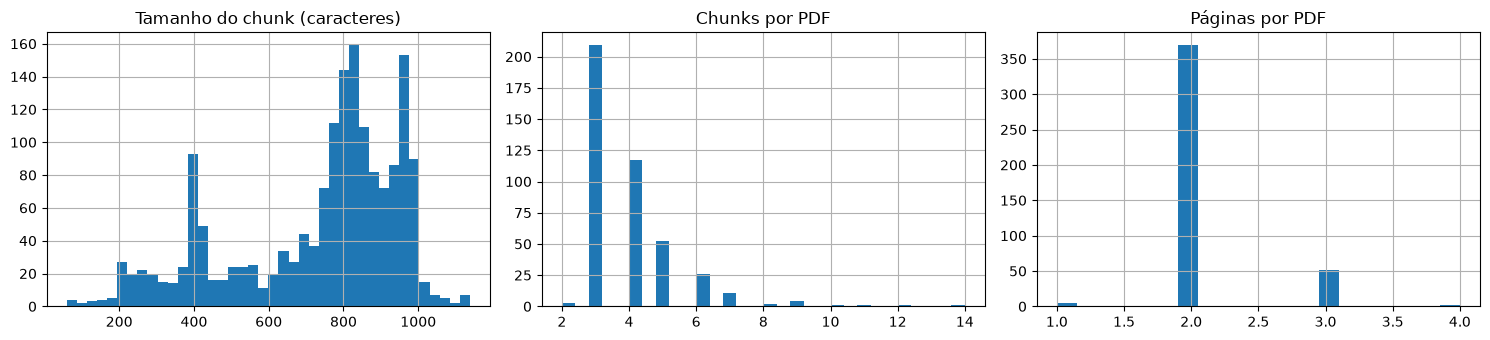

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df_pg = pd.DataFrame([dict(arquivo=p["arquivo"], chars=len(p["texto"])) for p in paginas])
df_ch = pd.DataFrame([dict(arquivo=c["arquivo"], campo=c["campo"], chars=len(c["texto"])) for c in chunks])
pdf_mb = sum(f.stat().st_size for f in PDF_DIR.glob("*.pdf")) / 1e6

estat_corpus = {
    "pdfs_baixados": len(list(PDF_DIR.glob("*.pdf"))),
    "campos_distintos": len(campos),
    "tamanho_pdfs_mb": round(pdf_mb, 1),
    "paginas_com_texto": len(df_pg),
    "paginas_por_pdf_media": round(df_pg.groupby("arquivo").size().mean(), 2),
    "caracteres_total": int(df_pg.chars.sum()),
    "tokens_estimados_total": int(df_pg.chars.sum() / 4),
    "pdfs_sem_texto_ocr": len(escaneados),
    "chunks": len(chunks),
    "chunks_por_pdf_media": round(df_ch.groupby("arquivo").size().mean(), 2),
    "chunk_chars_media": round(df_ch.chars.mean(), 1),
    "chunk_chars_mediana": float(df_ch.chars.median()),
    "chunk_chars_max": int(df_ch.chars.max()),
    "chunks_duplicados_pct": round(100 * (1 - df_ch.assign(t=[c["texto"] for c in chunks]).t.nunique() / len(chunks)), 2),
    "embedding_modelo": EMBED_MODEL,
    "embedding_dim": int(embeddings.shape[1]),
    "indice_faiss_vetores": int(index.ntotal),
    "indice_faiss_mb": round(embeddings.nbytes / 1e6, 1),
}
display(pd.Series(estat_corpus, name="valor").to_frame())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
df_ch.chars.hist(bins=40, ax=ax[0]); ax[0].set_title("Tamanho do chunk (caracteres)")
df_ch.groupby("arquivo").size().hist(bins=30, ax=ax[1]); ax[1].set_title("Chunks por PDF")
df_pg.groupby("arquivo").size().hist(bins=20, ax=ax[2]); ax[2].set_title("Páginas por PDF")
plt.tight_layout(); plt.show()

### 11.2 Testes automatizados do pipeline
Verificações de sanidade de cada etapa. Cada teste lança `AssertionError` se falhar; o resumo mostra o resultado e o tempo.

In [15]:
def t_pdfs_existem():
    faltam = [m["arquivo"] for m in manifesto if m["status"] == "ok" and not (PDF_DIR / m["arquivo"]).exists()]
    assert not faltam, faltam[:5]
    assert all(m["status"] == "ok" for m in manifesto), [m for m in manifesto if m["status"] != "ok"][:3]

def t_pdfs_tem_texto():
    assert len(escaneados) / len(sem_texto) < 0.02, f"{len(escaneados)} PDFs sem texto"

def t_limpeza():
    assert all("\x00" not in p["texto"] and " " not in p["texto"] for p in paginas)
    assert limpar_texto("pro-\ncesso   x\n\n\n\ny") == "processo x\n\ny"

def t_chunks_tamanho():
    mx = max(len(c["texto"]) for c in chunks)
    assert mx <= CHUNK_SIZE + CHUNK_OVERLAP + 10, mx      # o overlap pode exceder o alvo em até CHUNK_OVERLAP

def t_chunks_metadados():
    chaves = {"id", "campo", "arquivo", "url", "pagina", "texto"}
    assert all(chaves <= set(c) and c["texto"].strip() and c["pagina"] >= 1 for c in chunks)
    assert [c["id"] for c in chunks] == list(range(len(chunks)))

def t_divisao_texto_longo():
    txt = ("palavra " * 2000).strip()
    partes = dividir(txt)
    assert len(partes) > 1 and all(len(p) <= CHUNK_SIZE + CHUNK_OVERLAP + 10 for p in partes)
    assert set(" ".join(partes).split()) == {"palavra"}

def t_embeddings():
    assert embeddings.shape == (len(chunks), embedder.get_sentence_embedding_dimension())
    assert np.isfinite(embeddings).all()
    assert np.allclose(np.linalg.norm(embeddings, axis=1), 1, atol=1e-3)

def t_indice_faiss():
    assert index.ntotal == len(chunks)
    amostra_i = np.random.default_rng(0).choice(len(chunks), 50, replace=False)
    _, I = index.search(embeddings[amostra_i], 1)
    assert (I[:, 0] == amostra_i).mean() >= 0.9       # cada chunk se recupera como top-1 (exceto duplicatas exatas)

def t_detectar_campo():
    rng = random.Random(1)
    ams = rng.sample(campos, min(60, len(campos)))
    acertos = sum(detectar_campo(f"Fale sobre o campo {c}") == c for c in ams)
    assert acertos / len(ams) >= 0.95, f"{acertos}/{len(ams)}"
    assert detectar_campo("Qual a capital do Brasil?") is None
    if {"Albacora", "Albacora Leste"} <= set(campos):
        assert detectar_campo("campo de Albacora Leste") == "Albacora Leste"       # nome mais longo vence

def t_recuperar_filtro_e_ordem():
    c = campos[0]
    res, cd = recuperar(f"produção do campo {c}", k=5)
    assert cd == c and len(res) == 5 and all(r["campo"] == c for r in res)
    sc = [r["score"] for r in res]
    assert sc == sorted(sc, reverse=True)

def t_recuperar_modos():
    for m in ("denso", "bm25", "hibrido"):
        res, _ = recuperar("Qual a bacia do campo?", k=4, modo=m, filtrar=False)
        assert len(res) == 4, m

def t_prompt():
    res, _ = recuperar("Qual o operador do campo Abalone?", k=3)
    p = montar_prompt("PERGUNTA_X", res)
    assert "PERGUNTA_X" in p and all(f"[{i}]" in p for i in (1, 2, 3))

def t_geracao_extrativa():
    if os.environ.get("ANTHROPIC_API_KEY"): return
    res, _ = recuperar("Qual o operador do campo Abalone?", k=3)
    assert "extrativo" in gerar("x", res)

TESTES = [t_pdfs_existem, t_pdfs_tem_texto, t_limpeza, t_chunks_tamanho, t_chunks_metadados, t_divisao_texto_longo,
          t_embeddings, t_indice_faiss, t_detectar_campo, t_recuperar_filtro_e_ordem, t_recuperar_modos,
          t_prompt, t_geracao_extrativa]

import random, traceback
linhas = []
for t in TESTES:
    t0 = time.perf_counter()
    try: t(); st, msg = "PASSOU", ""
    except Exception as e: st, msg = "FALHOU", f"{type(e).__name__}: {e}"[:120]
    linhas.append(dict(teste=t.__name__, resultado=st, ms=round(1000 * (time.perf_counter() - t0)), detalhe=msg))
df_testes = pd.DataFrame(linhas)
display(df_testes)
print(f"{(df_testes.resultado == 'PASSOU').sum()}/{len(df_testes)} testes passaram")

,teste,resultado,ms,detalhe
0,t_pdfs_existem,PASSOU,15,
1,t_pdfs_tem_texto,PASSOU,0,
2,t_limpeza,PASSOU,1,
3,t_chunks_tamanho,PASSOU,0,
4,t_chunks_metadados,PASSOU,0,
5,t_divisao_texto_longo,PASSOU,0,
6,t_embeddings,PASSOU,1,
7,t_indice_faiss,PASSOU,6,
8,t_detectar_campo,PASSOU,40,
9,t_recuperar_filtro_e_ordem,PASSOU,19,


13/13 testes passaram


### 11.3 Gabarito sintético para avaliação do retrieval
Sem perguntas anotadas por especialistas, o gabarito é construído **automaticamente** a partir da ficha estruturada que abre cada sumário (`Operador do Contrato`, `Bacia`, `Estado`, `Fluido Principal`, `Início de Produção`). Para cada campo geramos perguntas em linguagem natural; o trecho **relevante** é todo chunk do mesmo PDF que contém a linha-resposta. Isso mede *retrieval* de forma objetiva, mas é um proxy: as perguntas são factuais e curtas — perguntas analíticas (“como será o desenvolvimento do campo?”) exigiriam julgamento humano.

In [16]:
FICHA = {
    "operador": (r"Operador do Contrato:[ \t]*([^\n]+)", "Quem é o operador do contrato do campo {c}?"),
    "bacia":    (r"Bacia:[ \t]*([^\n]+)",               "Em qual bacia sedimentar está o campo {c}?"),
    "estado":   (r"Estado:[ \t]*([^\n]+)",              "Em que estado brasileiro fica o campo {c}?"),
    "fluido":   (r"Fluido Principal:[ \t]*([^\n]+)",    "Qual é o fluido principal produzido no campo {c}?"),
    "inicio":   (r"In[ií]cio de Produ[çc][ãa]o:[ \t]*([\d/]{4,10})", "Quando começou a produção do campo {c}?"),
}
norm_ws = lambda s: re.sub(r"\s+", " ", s).strip().lower()

campo_por_arquivo = {c["arquivo"]: c["campo"] for c in chunks}
nomes_unicos = {n for n, q in Counter(campo_por_arquivo.values()).items() if q == 1}   # evita campos com nome repetido
texto_doc = {}
for p in paginas: texto_doc.setdefault(p["arquivo"], []).append(p["texto"])
chunks_norm = [norm_ws(c["texto"]) for c in chunks]
ids_por_arquivo = {}
for c in chunks: ids_por_arquivo.setdefault(c["arquivo"], []).append(c["id"])

gabarito = []
for arq, partes in texto_doc.items():
    campo = campo_por_arquivo.get(arq)
    if campo not in nomes_unicos: continue
    doc = "\n".join(partes)
    for tipo, (rx, modelo) in FICHA.items():
        m = re.search(rx, doc)
        if not m or len(m.group(1).strip()) < 2: continue
        span = norm_ws(m.group(0))
        rel = {i for i in ids_por_arquivo[arq] if span in chunks_norm[i]}
        if rel:
            gabarito.append(dict(tipo=tipo, campo=campo, arquivo=arq, pergunta=modelo.format(c=campo),
                                 resposta=m.group(1).strip(), relevantes=rel))
rng = random.Random(42); rng.shuffle(gabarito)
gabarito = gabarito[:1000]
print(len(gabarito), "perguntas |", dict(Counter(g["tipo"] for g in gabarito)))
pd.DataFrame(gabarito).drop(columns="relevantes").head(8)

1000 perguntas | {'inicio': 179, 'estado': 204, 'operador': 219, 'bacia': 189, 'fluido': 209}


,tipo,campo,arquivo,pergunta,resposta
0,inicio,Sul de Coruripe,sul_de_coruripe.pdf,Quando começou a produção do campo Sul de Coru...,05/1986
1,estado,Riacho da Forquilha,riacho-da-forquilha.pdf,Em que estado brasileiro fica o campo Riacho d...,Rio Grande do Norte
2,operador,Rio Subaúma,rio_subauma.pdf,Quem é o operador do contrato do campo Rio Sub...,PetroRecôncavo S.A.
3,bacia,Biriba,biriba.pdf,Em qual bacia sedimentar está o campo Biriba?,Recôncavo
4,operador,Carapanaúba,carapanauba.pdf,Quem é o operador do contrato do campo Carapan...,Petróleo Brasileiro S.A.
5,bacia,Canabrava,canabrava-1.pdf,Em qual bacia sedimentar está o campo Canabrava?,Recôncavo
6,fluido,Mossoró,mossoro.pdf,Qual é o fluido principal produzido no campo M...,Óleo
7,bacia,Sul de Lula,sul-de-lula.pdf,Em qual bacia sedimentar está o campo Sul de L...,Santos


### 11.4 Métricas de retrieval
Para cada pergunta (k = `TOP_K`): **Hit@k** (algum trecho relevante no top‑k = *context recall* binário), **Precision@k** (fração do top‑k que é relevante), **Recall@k** (relevantes recuperados ÷ relevantes existentes), **MRR**, **nDCG@k** e **Campo correto @1**. Latência medida com cache de embedding de consulta desligado.

Denso (sem filtro):   0%|          | 0/1000 [00:00<?, ?it/s]

Denso (sem filtro):  51%|█████     | 512/1000 [00:00<00:00, 5108.97it/s]

BM25 (sem filtro):   0%|          | 0/1000 [00:00<?, ?it/s]

BM25 (sem filtro):   5%|▌         | 50/1000 [00:00<00:01, 496.99it/s]

BM25 (sem filtro):  10%|█         | 100/1000 [00:00<00:01, 471.42it/s]

BM25 (sem filtro):  15%|█▍        | 148/1000 [00:00<00:01, 472.35it/s]

... (54 outputs left out)

Híbrido + filtro campo:  88%|████████▊ | 880/1000 [00:02<00:00, 433.59it/s]

Híbrido + filtro campo:  92%|█████████▏| 924/1000 [00:02<00:00, 433.81it/s]

Híbrido + filtro campo:  97%|█████████▋| 970/1000 [00:02<00:00, 438.62it/s]

,Hit@1,Hit@3,Hit@6,Precision@6,Recall@6,MRR,nDCG@6,Campo correto@1,Latência p50 (ms),Latência p95 (ms)
modo,,,,,,,,,,
Denso (sem filtro),0.567,0.886,0.971,0.162,0.97,0.730,0.790,0.948,6.093,10.351
BM25 (sem filtro),0.616,0.892,0.960,0.160,0.96,0.755,0.807,0.843,8.159,9.275
Híbrido RRF (sem filtro),0.597,0.933,0.980,0.164,0.98,0.765,0.820,0.940,8.358,9.399
Híbrido + filtro campo,0.615,0.976,1.000,0.167,1.00,0.789,0.843,1.000,8.798,9.857


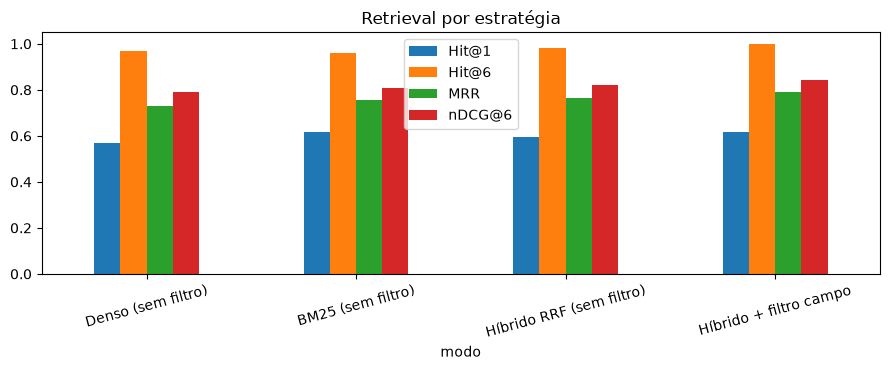


Híbrido + filtro de campo, por tipo de pergunta:


,hit1,hit3,hitk,precision,recall,mrr,ndcg,campo_top1
tipo,,,,,,,,
bacia,0.741,0.984,1.0,0.167,1.0,0.858,0.895,1.0
estado,0.745,0.995,1.0,0.167,1.0,0.869,0.903,1.0
fluido,0.144,0.904,1.0,0.167,1.0,0.503,0.630,1.0
inicio,0.592,1.000,1.0,0.167,1.0,0.791,0.845,1.0
operador,0.854,1.000,1.0,0.167,1.0,0.926,0.945,1.0


In [17]:
def metricas_pergunta(res, relevantes, campo_ok, k):
    ids = [r["id"] for r in res[:k]]
    rel = [1 if i in relevantes else 0 for i in ids]
    dcg = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(relevantes), k)))
    primeiro = next((p + 1 for p, r in enumerate(rel) if r), None)
    return dict(hit1=int(bool(rel[:1] and rel[0])), hit3=int(any(rel[:3])), hitk=int(any(rel)),
                precision=sum(rel) / k, recall=sum(rel) / len(relevantes),
                mrr=1 / primeiro if primeiro else 0.0, ndcg=dcg / idcg if idcg else 0.0,
                campo_top1=int(bool(res) and res[0]["campo"] == campo_ok))

MODOS = {
    "Denso (sem filtro)":       dict(modo="denso",   filtrar=False),
    "BM25 (sem filtro)":        dict(modo="bm25",    filtrar=False),
    "Híbrido RRF (sem filtro)": dict(modo="hibrido", filtrar=False),
    "Híbrido + filtro campo":   dict(modo="hibrido", filtrar=True),
}

# pré-codifica as consultas em lote (acelera a avaliação)
qs = [g["pergunta"] for g in gabarito]
_QCACHE.update(zip(qs, embedder.encode(["query: " + q for q in qs], batch_size=64, normalize_embeddings=True).astype("float32")))

linhas = []
for nome, kw in MODOS.items():
    for g in tqdm(gabarito, desc=nome, leave=False):
        res, _ = recuperar(g["pergunta"], k=TOP_K, **kw)
        linhas.append(dict(modo=nome, tipo=g["tipo"], **metricas_pergunta(res, g["relevantes"], g["campo"], TOP_K)))
df_ret = pd.DataFrame(linhas)

# latência (sem cache de consulta)
amostra_lat = [g["pergunta"] for g in gabarito[:100]]
lat = {}
for nome, kw in MODOS.items():
    ts = []
    for q in amostra_lat:
        _QCACHE.pop(q, None); t0 = time.perf_counter()
        recuperar(q, k=TOP_K, **kw); ts.append(1000 * (time.perf_counter() - t0))
    lat[nome] = (np.percentile(ts, 50), np.percentile(ts, 95))

tab = df_ret.groupby("modo").mean(numeric_only=True).loc[list(MODOS)]
tab.columns = ["Hit@1", "Hit@3", f"Hit@{TOP_K}", f"Precision@{TOP_K}", f"Recall@{TOP_K}", "MRR", f"nDCG@{TOP_K}", "Campo correto@1"]
tab["Latência p50 (ms)"] = [lat[m][0] for m in tab.index]
tab["Latência p95 (ms)"] = [lat[m][1] for m in tab.index]
display(tab.round(3))

ax = tab[["Hit@1", f"Hit@{TOP_K}", "MRR", f"nDCG@{TOP_K}"]].plot.bar(figsize=(9, 3.8), ylim=(0, 1.05), rot=15)
ax.set_title("Retrieval por estratégia"); plt.tight_layout(); plt.show()

print("\nHíbrido + filtro de campo, por tipo de pergunta:")
display(df_ret[df_ret.modo == "Híbrido + filtro campo"].groupby("tipo").mean(numeric_only=True).round(3))

### 11.5 Métricas de geração (requer `ANTHROPIC_API_KEY`)
Em uma amostra do gabarito, mede-se: **correção** (o valor esperado aparece na resposta), **taxa de citação** (a resposta cita `[n]`), **fidelidade** (um LLM-juiz verifica se *toda* afirmação está sustentada pelo contexto recuperado — *faithfulness/groundedness*), **relevância da resposta** (responde à pergunta?) e **abstenção correta** (perguntas sobre campos inexistentes devem ser recusadas). Sem chave, a célula apenas informa que foi pulada.

In [18]:
N_GER = 40
resultado_geracao = None
if not os.environ.get("ANTHROPIC_API_KEY"):
    print("ANTHROPIC_API_KEY não definida – avaliação de geração pulada.")
else:
    import anthropic
    cli = anthropic.Anthropic()
    def juiz(prompt):
        r = cli.messages.create(model=LLM_MODEL, max_tokens=200, messages=[{"role": "user", "content": prompt +
            '\n\nResponda SOMENTE com JSON: {"sim": true|false}'}])
        m = re.search(r"\{.*?\}", r.content[0].text, re.S)
        return bool(json.loads(m.group(0)).get("sim")) if m else False

    linhas = []
    for g in tqdm(gabarito[:N_GER], desc="geração"):
        res, _ = recuperar(g["pergunta"], k=TOP_K)
        ctx = "\n".join(t["texto"] for t in res)
        resp = gerar(g["pergunta"], res)
        linhas.append(dict(
            tipo=g["tipo"],
            correta=norm_ws(g["resposta"]) in norm_ws(resp),
            cita=bool(re.search(r"\[\d+\]", resp)),
            fiel=juiz(f"Contexto:\n{ctx}\n\nResposta:\n{resp}\n\nTodas as afirmações da resposta estão sustentadas pelo contexto?"),
            relevante=juiz(f"Pergunta: {g['pergunta']}\n\nResposta:\n{resp}\n\nA resposta aborda diretamente a pergunta?")))
    df_ger = pd.DataFrame(linhas)

    inexistentes = ["Quem é o operador do campo Zeta Inexistente 77?", "Qual a bacia do campo Narnia Offshore?",
                    "Quando começou a produção do campo Atlantida Verde?", "Qual o fluido do campo Xanadu?", "Qual o estado do campo Wakanda Sul?"]
    abst = []
    for q in inexistentes:
        res, _ = recuperar(q, k=TOP_K)
        resp = gerar(q, res)
        abst.append(juiz(f"Pergunta: {q}\n\nResposta:\n{resp}\n\nA resposta admite que não encontrou a informação nos documentos (em vez de inventar um valor)?"))

    resultado_geracao = {"amostra": len(df_ger), "correcao": df_ger.correta.mean(), "taxa_citacao": df_ger.cita.mean(),
                         "fidelidade": df_ger.fiel.mean(), "relevancia_resposta": df_ger.relevante.mean(),
                         "abstencao_correta": float(np.mean(abst)), "n_abstencao": len(abst)}
    display(pd.Series(resultado_geracao, name="valor").to_frame().round(3))

ANTHROPIC_API_KEY não definida – avaliação de geração pulada.


### 11.6 Consolidação das métricas
Salva tudo em `metricas_rag.json` (usado no README).

In [19]:
consolidado = {
    "corpus": estat_corpus,
    "testes": {"total": len(df_testes), "passaram": int((df_testes.resultado == "PASSOU").sum())},
    "gabarito": {"perguntas": len(gabarito), "por_tipo": dict(Counter(g["tipo"] for g in gabarito)), "top_k": TOP_K},
    "retrieval": tab.round(4).to_dict(orient="index"),
    "geracao": resultado_geracao,
}
(BASE_DIR / "metricas_rag.json").write_text(json.dumps(consolidado, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print(json.dumps(consolidado["retrieval"], ensure_ascii=False, indent=1)[:1500])

{
 "Denso (sem filtro)": {
  "Hit@1": 0.567,
  "Hit@3": 0.886,
  "Hit@6": 0.971,
  "Precision@6": 0.1618,
  "Recall@6": 0.9705,
  "MRR": 0.7296,
  "nDCG@6": 0.7902,
  "Campo correto@1": 0.948,
  "Latência p50 (ms)": 6.0926,
  "Latência p95 (ms)": 10.3505
 },
 "BM25 (sem filtro)": {
  "Hit@1": 0.616,
  "Hit@3": 0.892,
  "Hit@6": 0.96,
  "Precision@6": 0.16,
  "Recall@6": 0.9595,
  "MRR": 0.755,
  "nDCG@6": 0.8065,
  "Campo correto@1": 0.843,
  "Latência p50 (ms)": 8.1585,
  "Latência p95 (ms)": 9.2753
 },
 "Híbrido RRF (sem filtro)": {
  "Hit@1": 0.597,
  "Hit@3": 0.933,
  "Hit@6": 0.98,
  "Precision@6": 0.1635,
  "Recall@6": 0.98,
  "MRR": 0.7649,
  "nDCG@6": 0.8199,
  "Campo correto@1": 0.94,
  "Latência p50 (ms)": 8.3579,
  "Latência p95 (ms)": 9.3994
 },
 "Híbrido + filtro campo": {
  "Hit@1": 0.615,
  "Hit@3": 0.976,
  "Hit@6": 1.0,
  "Precision@6": 0.1668,
  "Recall@6": 1.0,
  "MRR": 0.789,
  "nDCG@6": 0.8433,
  "Campo correto@1": 1.0,
  "Latência p50 (ms)": 8.7984,
  "Latência p9